Handwritten Digit Recognition Classifier

In [31]:
# Import libraries

import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.datasets import mnist
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.optimizers import Adam

#matplotlib for visualisation
import matplotlib.pyplot as plt


In [32]:
# Load data
(X_train,y_train), (X_test,y_test) = mnist.load_data()

print(X_train.shape)
print(y_train.shape)

(60000, 28, 28)
(60000,)


Text(0.5, 1.1, 'Label, image')

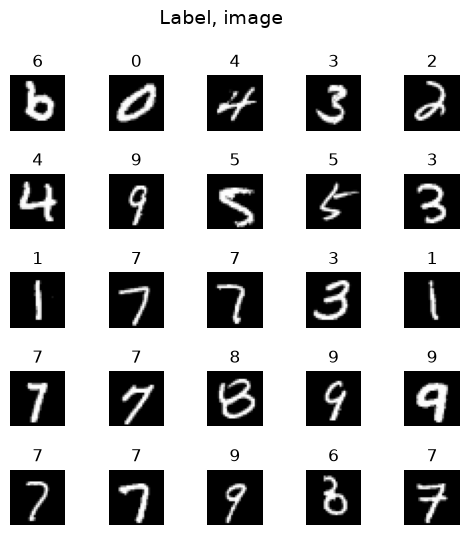

In [33]:
# Visualize image
#plt.imshow(X_train[2])

m = X_train.shape[0]
fig,axes = plt.subplots(5,5, figsize=(5,5))
fig.tight_layout(pad=0.5)

for i,ax in enumerate(axes.flat):
    random_idx = np.random.randint(m)
    X_reshaped = X_train[random_idx].reshape((28,28))
    ax.imshow(X_reshaped, cmap='gray')
    ax.set_axis_off()
    ax.set_title(y_train[random_idx])

fig.suptitle("Label, image", y=1.1, fontsize=14)


In [37]:
# Normalize the data

X_train = X_train/255.0
X_test = X_test/255.0

# Building a Neural Network Classifier

tf.random.set_seed(1234)

model = Sequential([
    Flatten(input_shape=(28,28)),
    Dense(128,activation='relu',name='L1'),
    Dense(64,activation='relu',name='L2'),
    Dense(10,activation='linear',name='L3')
])

model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_5 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L1 (Dense)                      │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L2 (Dense)                      │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L3 (Dense)                      │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
# Get layer weights
W1, b1 = model.get_layer('L1').get_weights()
W2, b2 = model.get_layer('L2').get_weights()
W3, b3 = model.get_layer('L3').get_weights()

print(W1.shape, b1.shape)
print(W2.shape, b2.shape)
print(W3.shape, b3.shape)

(784, 128) (128,)
(128, 64) (64,)
(64, 10) (10,)


In [41]:
# Define loss and optimizer

model.compile(
    loss = SparseCategoricalCrossentropy(from_logits=True),
    optimizer = Adam(learning_rate=0.0001),
    metrics=['accuracy']
)

model.fit(X_train,y_train,epochs=50,batch_size=32)

Epoch 1/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.9204 - loss: 0.2849
Epoch 2/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9208 - loss: 0.2839
Epoch 3/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9210 - loss: 0.2828
Epoch 4/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9213 - loss: 0.2819
Epoch 5/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9215 - loss: 0.2809
Epoch 6/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9217 - loss: 0.2801
Epoch 7/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9221 - loss: 0.2793
Epoch 8/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9222 - loss: 0.2785
Epoch 9/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9225 - loss: 0.2777
Epoch 10/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9228 - loss: 0.2770
Epoch 11/50
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9231 - loss: 0.2764
Epoch 12/50
1875/18